# 02 · Crescimento e receita

**Pergunta:** o negócio está crescendo? De onde vem a receita: quais categorias, regiões e vendedores sustentam o resultado?

Base: pedidos válidos (não cancelados nem indisponíveis). Séries mensais de jan/2017 a jul/2018; ago/2018 fica fora por estar incompleto (ver notebook 01).

## Principais conclusões

- **Crescimento forte e real.** Na comparação de jan–jul/2018 com o mesmo período de 2017, os pedidos cresceram 158% e a receita 161% (153% acima da inflação).
- **O crescimento veio do volume**, não do preço: o ticket médio ficou estável, perto de R$ 160.
- **Meados de 2018 tiveram choques externos.** O ritmo caiu de 233 pedidos/dia (jan–abr) para 203 (jun–jul), durante a greve dos caminhoneiros e a Copa, e voltou ao recorde de 273/dia em agosto.
- **Receita diversificada:** 18 das 74 categorias fazem 80% das vendas. Beleza e saúde, Relógios e presentes e Cama, mesa e banho lideram; Bebês (+363%), Relógios (+274%) e Beleza (+229%) crescem mais rápido.
- **Concentração geográfica:** o Sudeste tem 65% da receita e 42% da população. A penetração acompanha a renda (correlação de 0,80), e Norte e Nordeste são a fronteira de crescimento.
- **Vendedores:** os 10% maiores fazem 67% da receita, e 60% dos vendedores estão em SP.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from olist import config, data, prep, viz
from olist.viz import CORES, brl, num, pct

viz.aplicar_estilo()

In [2]:
t = data.carregar_todas()
pedidos = prep.carregar_base_pedidos()
validos = pedidos[pedidos.valido]
completos = validos[prep.no_periodo(validos.order_purchase_timestamp, config.INICIO_JANELA, config.FIM_MES_COMPLETO)]

itens = prep.base_itens(t)
itens = itens[itens.valido & prep.no_periodo(itens.order_purchase_timestamp, config.INICIO_JANELA, config.FIM_JANELA)]

## 1. Números gerais da janela (jan/2017 a ago/2018)

In [3]:
pd.Series({
    "Pedidos": num(len(validos)),
    "Receita (GMV)": brl(validos.gmv.sum()),
    "  dos quais produtos": brl(validos.valor_produtos.sum()),
    "  dos quais frete": brl(validos.valor_frete.sum()),
    "Ticket médio por pedido": brl(validos.gmv.mean()),
    "Clientes únicos": num(validos.customer_unique_id.nunique()),
    "Vendedores com venda": num(itens.seller_id.nunique()),
    "Categorias de produto": num(itens.categoria.nunique()),
}).to_frame("valor")

,valor
Pedidos,97.905
Receita (GMV),"R$ 15,7 mi"
dos quais produtos,"R$ 13,4 mi"
dos quais frete,"R$ 2,2 mi"
Ticket médio por pedido,R$ 160
Clientes únicos,94.703
Vendedores com venda,3.029
Categorias de produto,74


## 2. Evolução mensal

In [4]:
mensal = completos.groupby("mes").agg(
    pedidos=("order_id", "size"),
    gmv=("gmv", "sum"),
    clientes=("customer_unique_id", "nunique"),
)
mensal["ticket_medio"] = mensal.gmv / mensal.pedidos

# Receita real a preços de jul/2018, deflacionada pelo IPCA (Banco Central)
ipca = data.carregar_ipca().set_index("mes").ipca_pct
indice = (1 + ipca / 100).cumprod()
mensal["gmv_real"] = mensal.gmv * indice.loc[mensal.index.max()] / indice.reindex(mensal.index)

def acumulado(ano):
    return mensal.loc[f"{ano}-01-01":f"{ano}-07-01"].sum()

a17, a18 = acumulado(2017), acumulado(2018)
crescimento = pd.DataFrame({
    "jan–jul/2017": [num(a17.pedidos), brl(a17.gmv), brl(a17.gmv_real), brl(a17.gmv / a17.pedidos)],
    "jan–jul/2018": [num(a18.pedidos), brl(a18.gmv), brl(a18.gmv_real), brl(a18.gmv / a18.pedidos)],
    "variação": [pct(a18.pedidos / a17.pedidos - 1), pct(a18.gmv / a17.gmv - 1), pct(a18.gmv_real / a17.gmv_real - 1),
                 pct((a18.gmv / a18.pedidos) / (a17.gmv / a17.pedidos) - 1)],
}, index=["Pedidos", "Receita nominal", "Receita real (preços de jul/18)", "Ticket médio"])
crescimento

,jan–jul/2017,jan–jul/2018,variação
Pedidos,18.290,47.109,"157,6%"
Receita nominal,"R$ 2,9 mi","R$ 7,6 mi","160,8%"
Receita real (preços de jul/18),"R$ 3,1 mi","R$ 7,7 mi","152,9%"
Ticket médio,R$ 159,R$ 161,"1,2%"


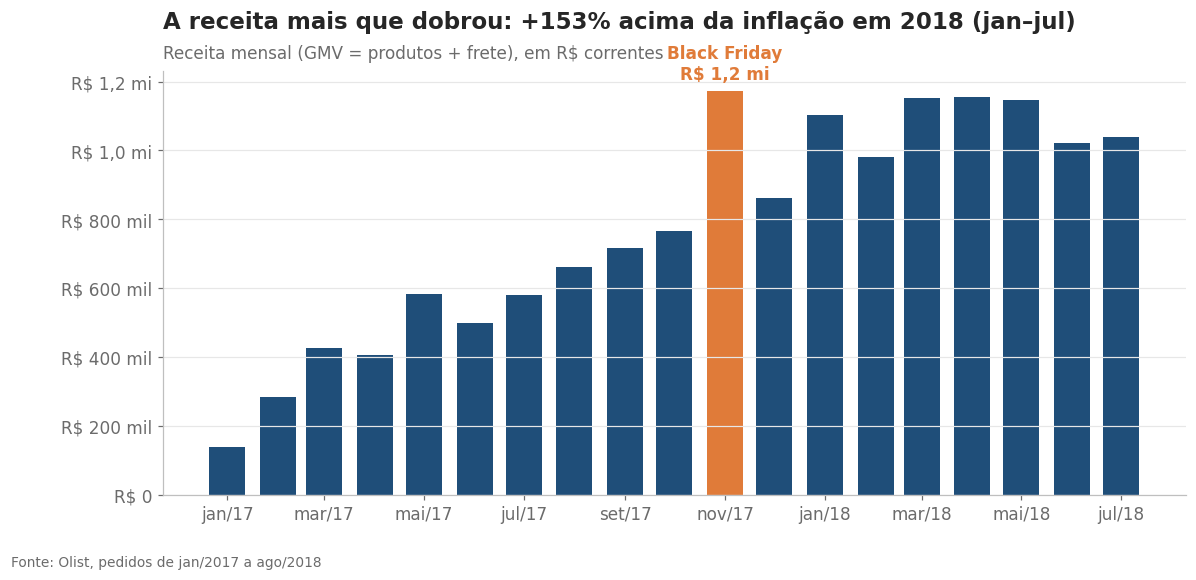

In [5]:
cresc_real = a18.gmv_real / a17.gmv_real - 1
bf = pd.Timestamp("2017-11-01")

fig, ax = plt.subplots(figsize=(12, 5))
cores = [CORES["destaque"] if m == bf else CORES["principal"] for m in mensal.index]
ax.bar(mensal.index, mensal.gmv, width=22, color=cores)
ax.annotate(f"Black Friday\n{brl(mensal.loc[bf, 'gmv'])}", xy=(bf, mensal.loc[bf, "gmv"]), xytext=(0, 8),
            textcoords="offset points", ha="center", color=CORES["destaque"], fontweight="bold")
ax.yaxis.set_major_formatter(viz.eixo_brl)
ax.xaxis.set_major_formatter(viz.eixo_mes)
viz.titulo(ax, f"A receita mais que dobrou: +{pct(cresc_real, 0)} acima da inflação em 2018 (jan–jul)",
           "Receita mensal (GMV = produtos + frete), em R$ correntes")
viz.fonte(fig)
viz.salvar(fig, "02_receita_mensal")

### O ritmo de 2018

Para incluir agosto/2018 sem a distorção do corte da extração, comparamos o **ritmo diário** (pedidos por dia) de cada mês, usando para agosto só os dias 1 a 21. Dois eventos externos marcam o meio de 2018: a **greve dos caminhoneiros** (21/05 a 03/06), que paralisou a logística do país, e a **Copa do Mundo** (14/06 a 15/07).

Ritmo de jan–abr/2018: 233 pedidos/dia
Ritmo de jun–jul/2018: 203 pedidos/dia
Ritmo de ago/2018 (até dia 21): 273 pedidos/dia (35,9% sobre julho; maior marca anterior: 247)
Ticket médio: de R$ 147 a R$ 174 no período


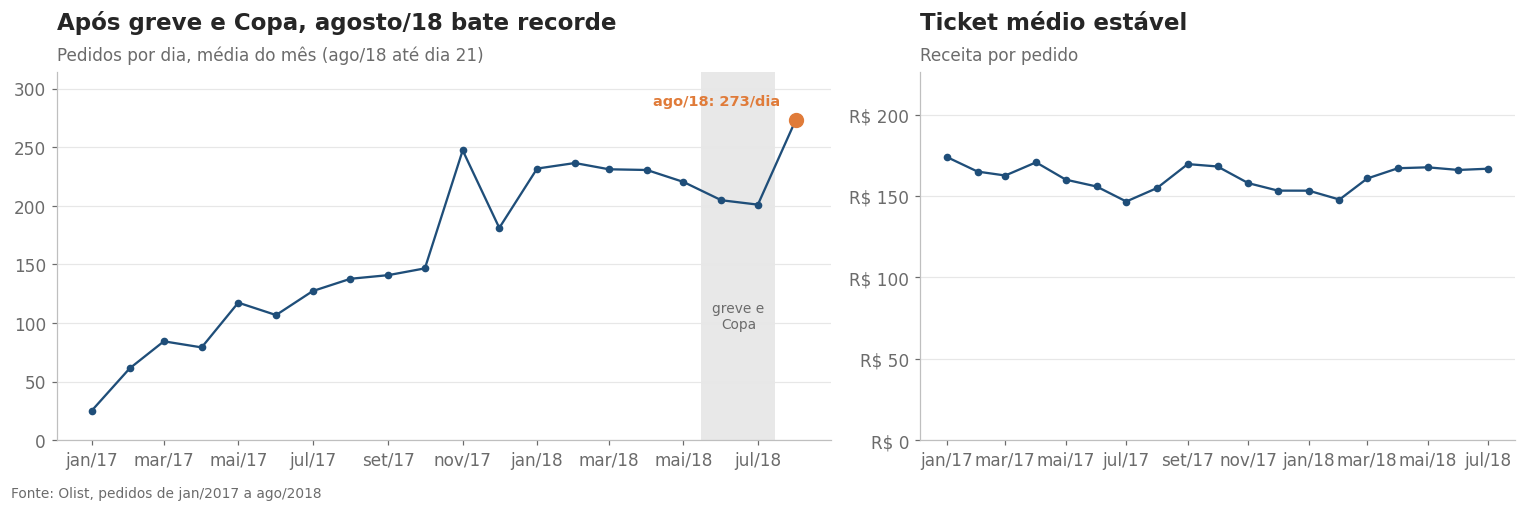

In [6]:
diario_validos = validos[prep.no_periodo(validos.order_purchase_timestamp, config.INICIO_JANELA, config.FIM_SERIE_DIARIA)]
ritmo = diario_validos.groupby("mes").size().to_frame("pedidos")
ritmo["dias"] = ritmo.index.days_in_month
ritmo.loc["2018-08-01", "dias"] = 21
ritmo["por_dia"] = ritmo.pedidos / ritmo.dias
recorde_anterior = ritmo.loc[:"2018-07-01", "por_dia"].max()
agosto = ritmo.loc["2018-08-01", "por_dia"]
print(f"Ritmo de jan–abr/2018: {num(ritmo.loc['2018-01-01':'2018-04-01', 'por_dia'].mean())} pedidos/dia")
print(f"Ritmo de jun–jul/2018: {num(ritmo.loc['2018-06-01':'2018-07-01', 'por_dia'].mean())} pedidos/dia")
print(f"Ritmo de ago/2018 (até dia 21): {num(agosto)} pedidos/dia ({pct(agosto / ritmo.loc['2018-07-01', 'por_dia'] - 1)} sobre julho; maior marca anterior: {num(recorde_anterior)})")
print(f"Ticket médio: de {brl(mensal.ticket_medio.min())} a {brl(mensal.ticket_medio.max())} no período")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.plot(ritmo.index, ritmo.por_dia, color=CORES["principal"], marker="o", ms=4)
ax.plot(ritmo.index[-1], agosto, marker="o", ms=9, color=CORES["destaque"])
ax.axvspan(pd.Timestamp("2018-05-15"), pd.Timestamp("2018-07-15"), color=CORES["neutro"], alpha=0.25, lw=0)
ax.text(pd.Timestamp("2018-06-15"), ritmo.por_dia.max() * 0.35, "greve e\nCopa", ha="center", fontsize=9, color=CORES["subtexto"])
ax.annotate(f"ago/18: {num(agosto)}/dia", (ritmo.index[-1], agosto), xytext=(-10, 10), textcoords="offset points", ha="right",
            color=CORES["destaque"], fontweight="bold", fontsize=9.5)
ax.yaxis.set_major_formatter(viz.eixo_num)
ax.xaxis.set_major_formatter(viz.eixo_mes)
ax.set_ylim(0, ritmo.por_dia.max() * 1.15)
viz.titulo(ax, "Após greve e Copa, agosto/18 bate recorde", "Pedidos por dia, média do mês (ago/18 até dia 21)")
ax = axes[1]
ax.plot(mensal.index, mensal.ticket_medio, color=CORES["principal"], marker="o", ms=4)
ax.set_ylim(0, mensal.ticket_medio.max() * 1.3)
ax.yaxis.set_major_formatter(viz.eixo_brl)
ax.xaxis.set_major_formatter(viz.eixo_mes)
viz.titulo(ax, "Ticket médio estável", "Receita por pedido")
fig.tight_layout()
viz.fonte(fig)
viz.salvar(fig, "02_volume_ticket")

## 3. Quando o cliente compra

Pedidos em dias úteis: 77,0% | entre 10h e 22h: 75,7%


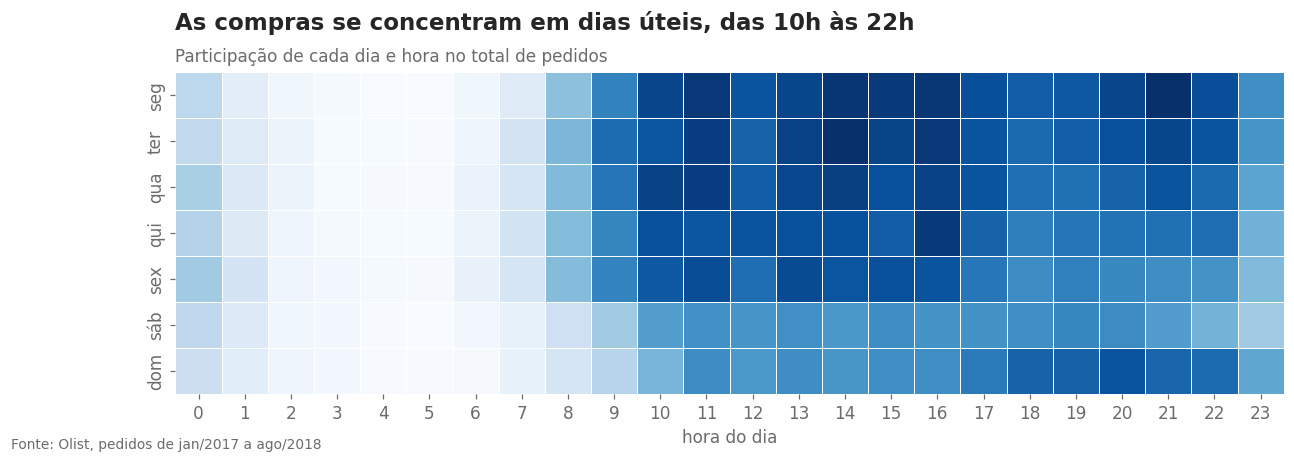

In [7]:
dias_semana = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
ts = validos.order_purchase_timestamp
calor = validos.assign(dia=ts.dt.dayofweek, hora=ts.dt.hour).pivot_table(index="dia", columns="hora", values="order_id", aggfunc="size")
calor = calor / calor.values.sum()
calor.index = dias_semana

uteis = calor.loc["seg":"sex"].values.sum()
comercial = calor.loc[:, 10:21].values.sum()
print(f"Pedidos em dias úteis: {pct(uteis)} | entre 10h e 22h: {pct(comercial)}")

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(calor, cmap="Blues", cbar=False, ax=ax, linewidths=0.5, linecolor="white")
ax.set_xlabel("hora do dia")
ax.set_ylabel("")
ax.grid(False)
viz.titulo(ax, "As compras se concentram em dias úteis, das 10h às 22h", "Participação de cada dia e hora no total de pedidos")
viz.fonte(fig)
viz.salvar(fig, "02_dia_hora")

## 4. Categorias

A receita por categoria considera só o valor dos produtos (sem frete).

In [8]:
cat = itens.groupby("categoria").agg(receita=("price", "sum"), itens=("order_item_id", "size"), pedidos=("order_id", "nunique"))
cat = cat.sort_values("receita", ascending=False)
cat["participacao"] = cat.receita / cat.receita.sum()
cat["acumulado"] = cat.participacao.cumsum()
n80 = int((cat.acumulado < 0.8).sum() + 1)
print(f"{n80} de {len(cat)} categorias concentram 80% da receita de produtos")
print(f"As 10 maiores somam {pct(cat.participacao.head(10).sum())}")

def receita_periodo(ano):
    filtro = prep.no_periodo(itens.order_purchase_timestamp, f"{ano}-01-01", f"{ano}-07-31")
    return itens[filtro].groupby("categoria").price.sum()

cat["crescimento"] = receita_periodo(2018) / receita_periodo(2017) - 1
cat.head(15).assign(
    receita=lambda d: d.receita.map(brl),
    participacao=lambda d: d.participacao.map(pct),
    acumulado=lambda d: d.acumulado.map(pct),
    crescimento=lambda d: d.crescimento.map(pct),
)

18 de 74 categorias concentram 80% da receita de produtos
As 10 maiores somam 62,4%


,receita,itens,pedidos,participacao,acumulado,crescimento
categoria,,,,,,
Beleza e saúde,"R$ 1,3 mi",9585,8757,"9,3%","9,3%","228,6%"
Relógios e presentes,"R$ 1,2 mi",5965,5599,"8,9%","18,2%","273,9%"
"Cama, mesa e banho","R$ 1,0 mi",11089,9394,"7,7%","25,9%","135,2%"
Esporte e lazer,R$ 978 mil,8573,7656,"7,3%","33,2%","161,8%"
Informática e acessórios,R$ 903 mil,7760,6636,"6,7%","39,9%","150,3%"
Móveis e decoração,R$ 722 mil,8229,6373,"5,4%","45,2%","137,1%"
Utilidades domésticas,R$ 626 mil,6903,5838,"4,7%","49,9%","214,6%"
Cool stuff,R$ 620 mil,3772,3609,"4,6%","54,5%","24,0%"
Automotivo,R$ 585 mil,4195,3863,"4,4%","58,8%","178,3%"


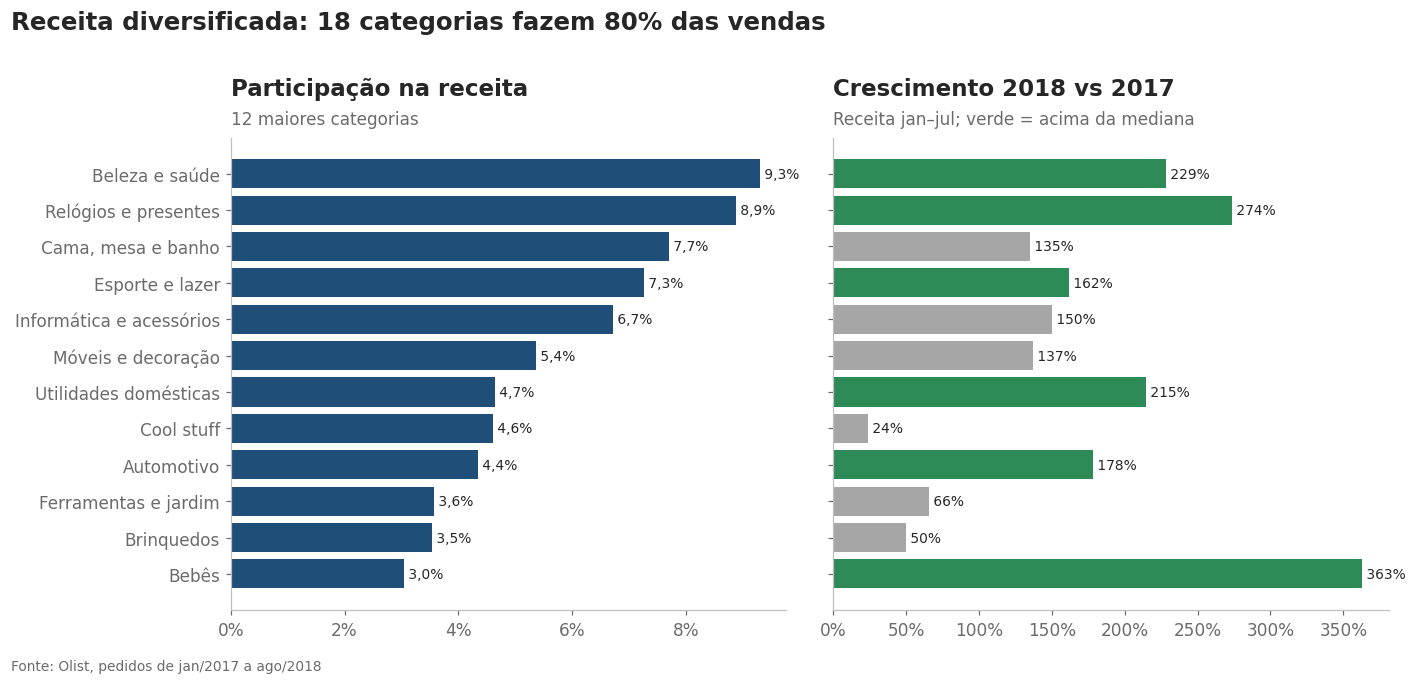

In [9]:
top = cat.head(12).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
ax = axes[0]
ax.barh(top.index, top.participacao, color=CORES["principal"])
for y, v in enumerate(top.participacao):
    ax.text(v, y, f" {pct(v)}", va="center", fontsize=9)
ax.xaxis.set_major_formatter(viz.eixo_pct)
ax.grid(axis="y", visible=False)
viz.titulo(ax, "Participação na receita", "12 maiores categorias")
ax = axes[1]
cores = [CORES["positivo"] if v >= cat.crescimento.loc[cat.index[:12]].median() else CORES["neutro"] for v in top.crescimento]
ax.barh(top.index, top.crescimento, color=cores)
for y, v in enumerate(top.crescimento):
    ax.text(v, y, f" {pct(v, 0)}", va="center", fontsize=9)
ax.xaxis.set_major_formatter(viz.eixo_pct)
ax.grid(axis="y", visible=False)
viz.titulo(ax, "Crescimento 2018 vs 2017", "Receita jan–jul; verde = acima da mediana")
fig.suptitle(f"Receita diversificada: {n80} categorias fazem 80% das vendas", x=0.01, ha="left", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
viz.fonte(fig)
viz.salvar(fig, "02_categorias")

## 5. Regiões

Cruzamos as vendas com população e PIB estaduais do IBGE (2018) para medir **penetração**: quantos clientes a operação tem para cada 100 mil habitantes.

In [10]:
uf = validos.groupby("customer_state").agg(pedidos=("order_id", "size"), gmv=("gmv", "sum"), clientes=("customer_unique_id", "nunique"))
uf = uf.join(data.carregar_populacao_uf().set_index("uf")).join(data.carregar_pib_uf().set_index("uf"))
uf["regiao"] = uf.index.map(config.UF_REGIAO)
uf["clientes_100k"] = uf.clientes / uf.populacao * 1e5
uf["pib_per_capita"] = uf.pib_mil_reais * 1000 / uf.populacao

regiao = uf.groupby("regiao")[["pedidos", "gmv", "populacao", "pib_mil_reais"]].sum().reindex(config.ORDEM_REGIOES)
pd.DataFrame({
    "% da receita": (regiao.gmv / regiao.gmv.sum()).map(pct),
    "% da população": (regiao.populacao / regiao.populacao.sum()).map(pct),
    "% do PIB": (regiao.pib_mil_reais / regiao.pib_mil_reais.sum()).map(pct),
    "clientes por 100 mil hab.": (uf.groupby("regiao").clientes.sum() / regiao.populacao * 1e5).map(num),
}).reindex(config.ORDEM_REGIOES)

,% da receita,% da população,% do PIB,clientes por 100 mil hab.
regiao,,,,
Sudeste,"64,6%","42,1%","53,1%",74
Sul,"14,5%","14,3%","17,1%",45
Centro-Oeste,"6,4%","7,7%","9,9%",34
Nordeste,"11,9%","27,2%","14,3%",16
Norte,"2,6%","8,7%","5,5%",10


Correlação entre PIB per capita e penetração: 0.80
SP: 37,4% da receita com 21,8% da população


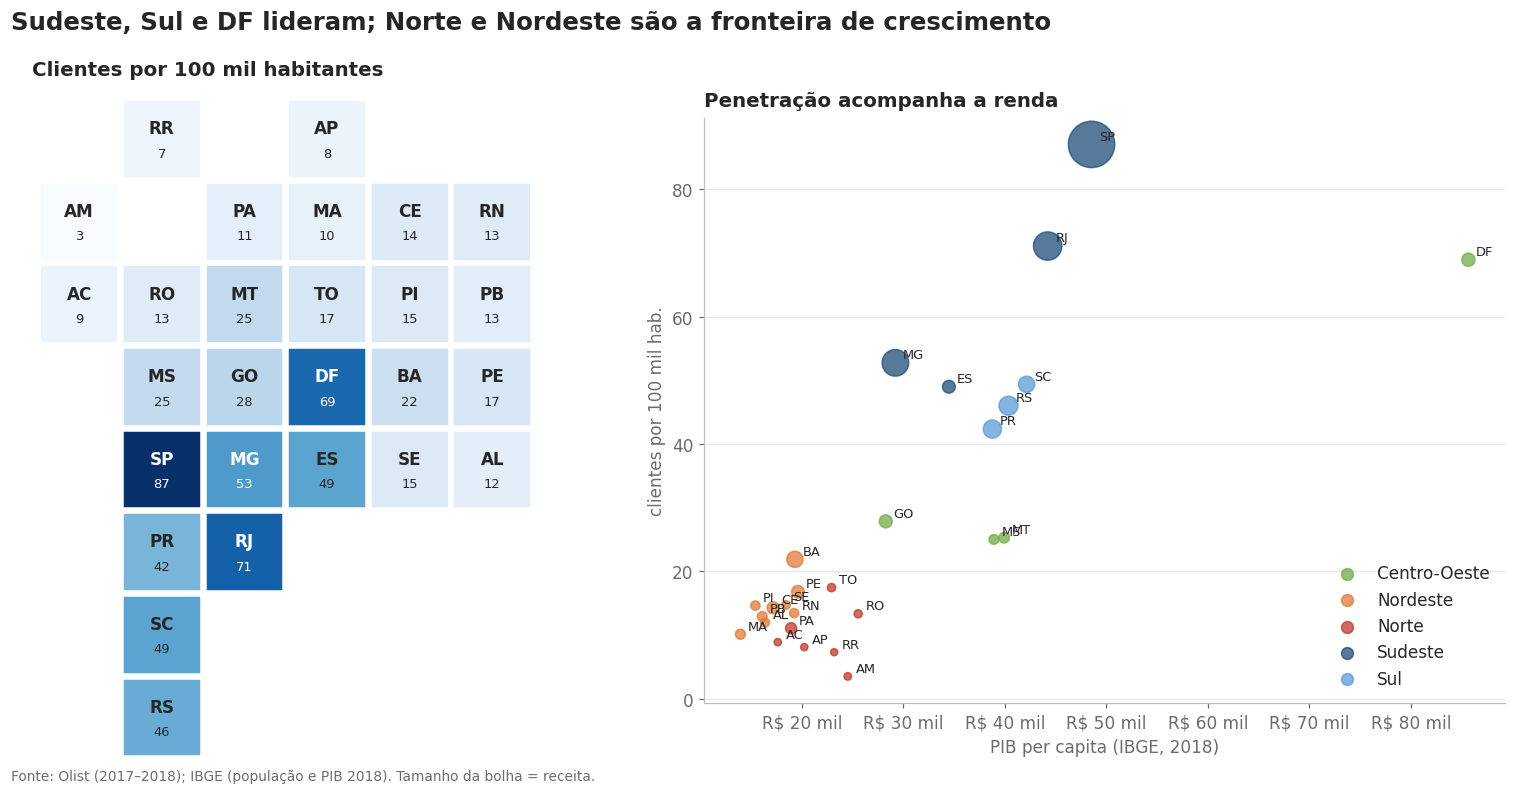

In [11]:
correlacao = uf[["pib_per_capita", "clientes_100k"]].corr().iloc[0, 1]
print(f"Correlação entre PIB per capita e penetração: {correlacao:.2f}")
print(f"SP: {pct(uf.loc['SP', 'gmv'] / uf.gmv.sum())} da receita com {pct(uf.loc['SP', 'populacao'] / uf.populacao.sum())} da população")

fig = plt.figure(figsize=(14, 7))
ax_mapa = fig.add_axes([0.0, 0.0, 0.38, 0.88])
viz.mapa_uf(uf.clientes_100k, ax=ax_mapa, cmap="Blues", formato=lambda v: num(v))
ax_mapa.set_title("Clientes por 100 mil habitantes", fontsize=13, pad=8)
ax = fig.add_axes([0.46, 0.08, 0.52, 0.76])
for reg, g in uf.groupby("regiao"):
    ax.scatter(g.pib_per_capita, g.clientes_100k, s=g.gmv / uf.gmv.max() * 900 + 20, color=viz.CORES_REGIAO[reg], alpha=0.75, label=reg)
for sigla, linha in uf.iterrows():
    ax.annotate(sigla, (linha.pib_per_capita, linha.clientes_100k), xytext=(5, 3), textcoords="offset points", fontsize=8.5)
ax.xaxis.set_major_formatter(viz.eixo_brl)
ax.set_xlabel("PIB per capita (IBGE, 2018)")
ax.set_ylabel("clientes por 100 mil hab.")
legenda = ax.legend(loc="lower right")
for marcador in legenda.legend_handles:
    marcador.set_sizes([60])
ax.set_title("Penetração acompanha a renda", fontsize=13, pad=8)
fig.suptitle("Sudeste, Sul e DF lideram; Norte e Nordeste são a fronteira de crescimento", x=0.01, ha="left", fontsize=16, fontweight="bold")
viz.fonte(fig, "Fonte: Olist (2017–2018); IBGE (população e PIB 2018). Tamanho da bolha = receita.")
viz.salvar(fig, "02_penetracao_uf")

## 6. Vendedores e produtos

3.029 vendedores com venda; os 10% maiores fazem 67,3% da receita, os 20% maiores, 82,5%
32.578 produtos vendidos; o 1% mais vendido responde por 24,5% da receita
Vendedores sediados em SP: 59,7% da base, 64,4% da receita


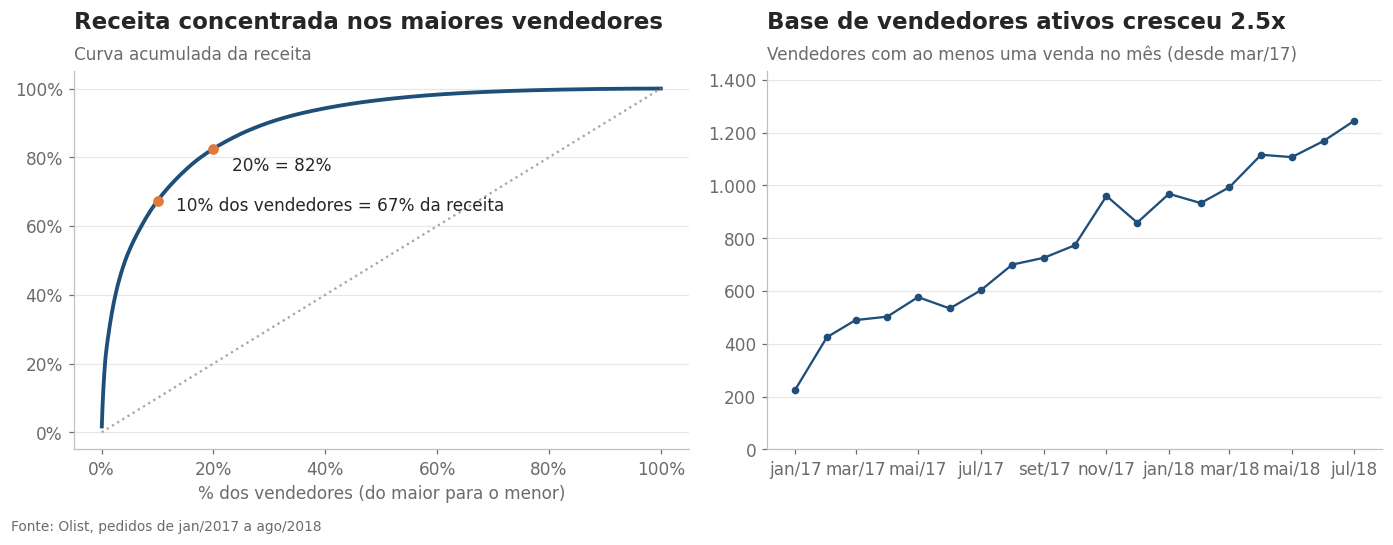

In [12]:
receita_seller = itens.groupby("seller_id").price.sum().sort_values(ascending=False)
curva = receita_seller.cumsum() / receita_seller.sum()
fracao = np.arange(1, len(curva) + 1) / len(curva)
top10 = curva.iloc[int(len(curva) * 0.10) - 1]
top20 = curva.iloc[int(len(curva) * 0.20) - 1]
print(f"{num(len(receita_seller))} vendedores com venda; os 10% maiores fazem {pct(top10)} da receita, os 20% maiores, {pct(top20)}")

receita_produto = itens.groupby("product_id").price.sum().sort_values(ascending=False)
top1_prod = receita_produto.head(int(len(receita_produto) * 0.01)).sum() / receita_produto.sum()
print(f"{num(len(receita_produto))} produtos vendidos; o 1% mais vendido responde por {pct(top1_prod)} da receita")

seller_uf = itens.groupby("seller_state").price.sum().sort_values(ascending=False) / itens.price.sum()
vendedores_uf = t["sellers"].seller_state.value_counts(normalize=True)
print(f"Vendedores sediados em SP: {pct(vendedores_uf['SP'])} da base, {pct(seller_uf['SP'])} da receita")

ativos = itens[prep.no_periodo(itens.order_purchase_timestamp, config.INICIO_JANELA, config.FIM_MES_COMPLETO)].groupby("mes").seller_id.nunique()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
ax.plot(fracao, curva.values, color=CORES["principal"], lw=2.5)
ax.plot([0, 1], [0, 1], color=CORES["neutro"], ls=":")
ax.scatter([0.1, 0.2], [top10, top20], color=CORES["destaque"], zorder=3)
ax.annotate(f"10% dos vendedores = {pct(top10, 0)} da receita", (0.1, top10), xytext=(12, -6), textcoords="offset points")
ax.annotate(f"20% = {pct(top20, 0)}", (0.2, top20), xytext=(12, -14), textcoords="offset points")
ax.xaxis.set_major_formatter(viz.eixo_pct)
ax.yaxis.set_major_formatter(viz.eixo_pct)
ax.set_xlabel("% dos vendedores (do maior para o menor)")
viz.titulo(ax, "Receita concentrada nos maiores vendedores", "Curva acumulada da receita")
ax = axes[1]
ax.plot(ativos.index, ativos.values, color=CORES["principal"], marker="o", ms=4)
ax.yaxis.set_major_formatter(viz.eixo_num)
ax.xaxis.set_major_formatter(viz.eixo_mes)
ax.set_ylim(0, ativos.max() * 1.15)
viz.titulo(ax, f"Base de vendedores ativos cresceu {ativos.iloc[-1] / ativos.loc['2017-03-01'] :.1f}x", "Vendedores com ao menos uma venda no mês (desde mar/17)")
fig.tight_layout()
viz.fonte(fig)
viz.salvar(fig, "02_vendedores")